# 4 · Metrics and Evaluation

This notebook evaluates the saved predictions from notebook 2 and the clusterings from notebook 3, and runs extra
experiments that explain *why* the models behave as they do.

1. Classification metrics on the random split – accuracy, precision, recall, F1 (macro & weighted)
2. Confusion matrices
3. The same models under contributor-disjoint and narrator-disjoint evaluation, with bootstrap confidence intervals
4. How much speech is needed? (accuracy vs duration)
5. Ablations – augmentation and feature groups
6. Clustering metrics – silhouette, purity, ARI / NMI

In [1]:
%load_ext autoreload
%autoreload 2
import os, warnings; warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import classification_report
from slid import config as C, features, models, plotting
plotting.setup(); RS = C.RANDOM_STATE
PROBA = [f"p_{l}" for l in C.LANGUAGES]
ORDER = ["SVM (RBF)", "Logistic Regression", "MLP", "KNN", "Random Forest", "Gaussian NB"]
PROTOCOLS = {"random split": "random_split", "contributor-disjoint": "contributor_cv", "narrator-disjoint (LONO)": "narrator_lono"}

seg_pred = {k: pd.read_csv(C.RESULTS_DIR / f"{v}_predictions.csv") for k, v in PROTOCOLS.items()}
file_pred = {k: models.file_level(v, PROBA) for k, v in seg_pred.items()}
meta = pd.read_parquet(C.PROCESSED_DIR / "metadata.parquet").set_index("file_id")

def table(pred):
    return pd.DataFrame({m: models.metrics(d.y_true, d.y_pred) for m, d in pred.groupby("model")}).T.reindex(ORDER)

## 4.1 Classification metrics – random 80/20 split (standard protocol)

In [2]:
metrics_random = pd.concat({"segment (10 s)": table(seg_pred["random split"]), "file (~1 min)": table(file_pred["random split"])}, axis=1)
metrics_random.to_csv(C.RESULTS_DIR / "metrics_random_split.csv")
metrics_random.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0)

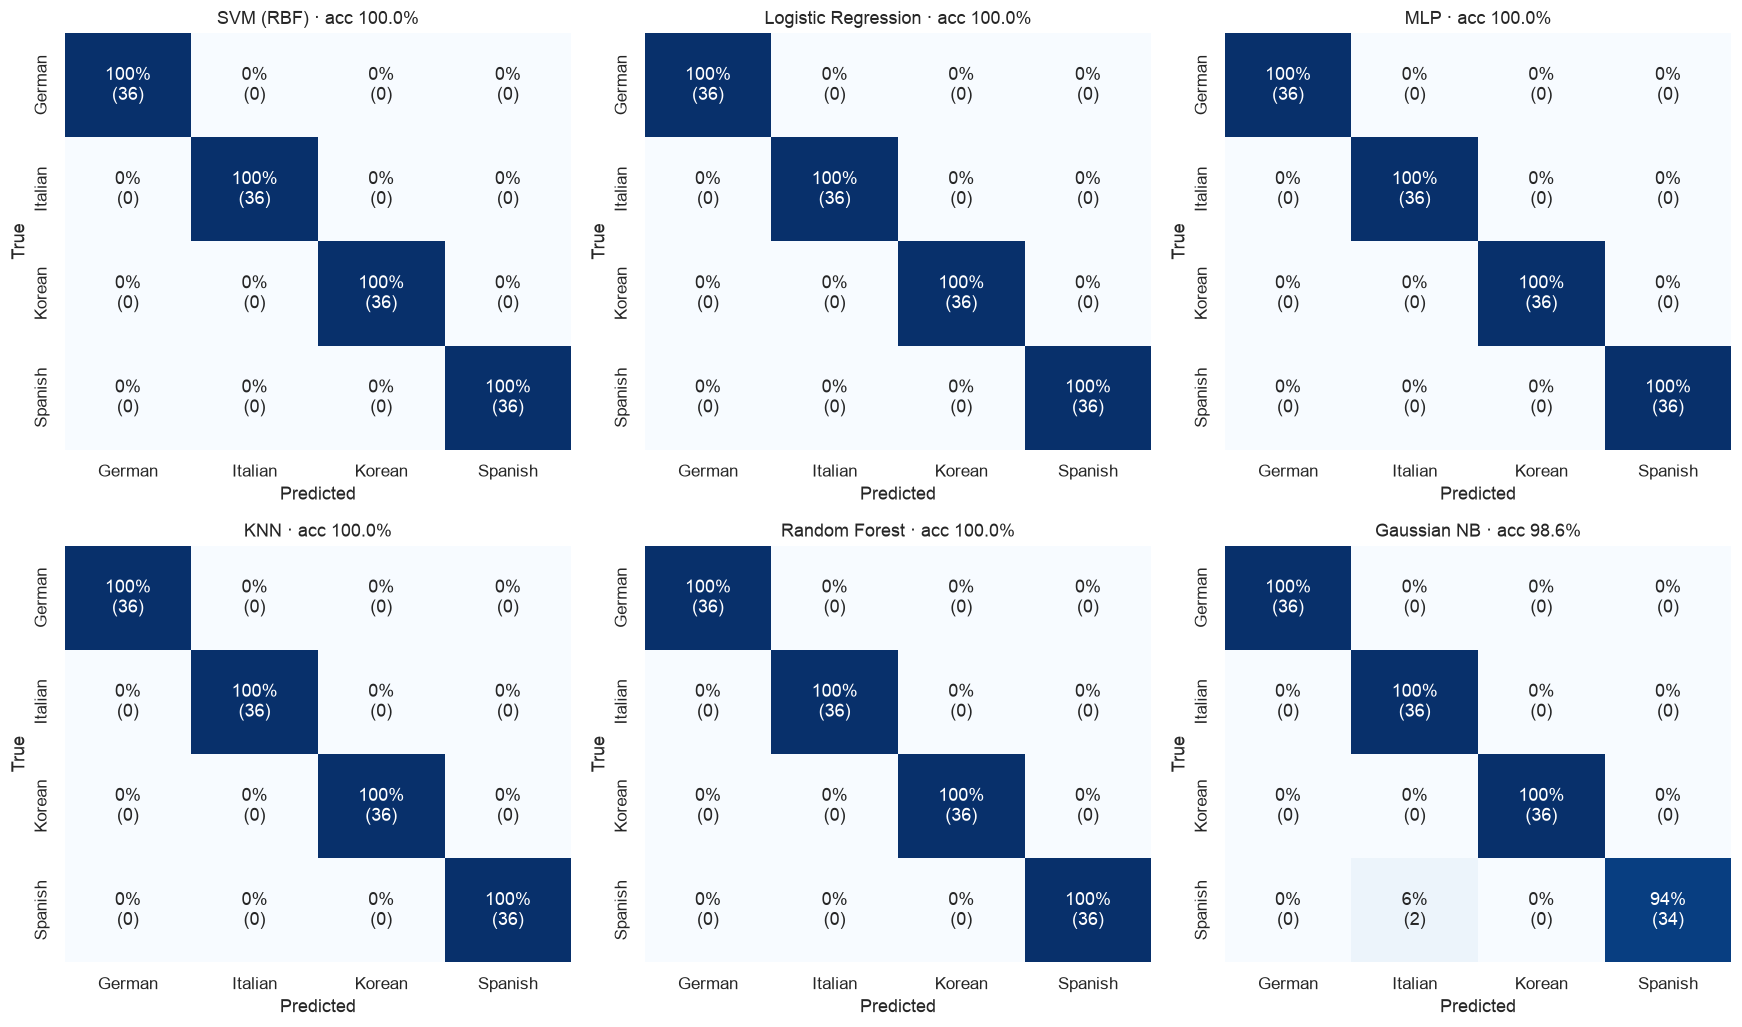

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
fr = file_pred["random split"]
for ax, m in zip(axes.flat, ORDER):
    d = fr[fr.model == m]
    plotting.confusion(ax, d.y_true, d.y_pred, f"{m} · acc {np.mean(d.y_true == d.y_pred):.1%}")
plt.tight_layout(); plotting.save(fig, "04_confusion_random_split")

              precision    recall  f1-score   support

      German      0.990     0.969     0.979       195
     Italian      0.912     0.995     0.952       199
      Korean      0.968     0.984     0.976       183
     Spanish      0.989     0.905     0.945       200

    accuracy                          0.963       777
   macro avg      0.965     0.963     0.963       777
weighted avg      0.965     0.963     0.963       777



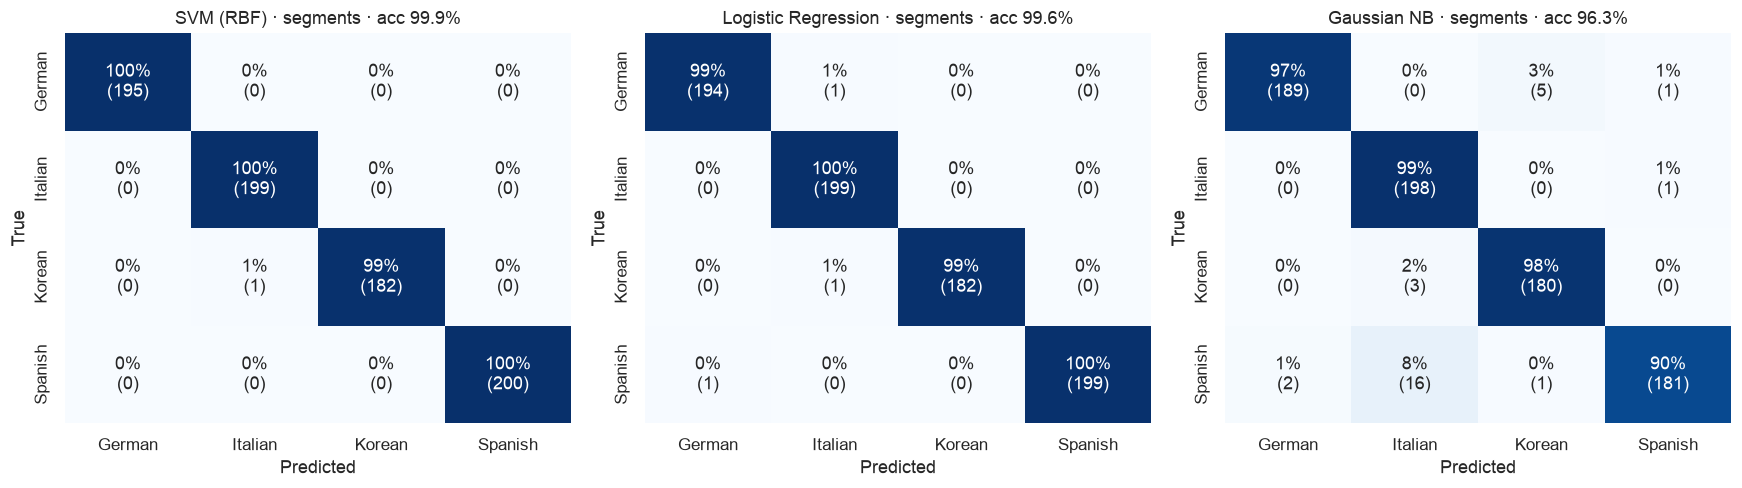

In [4]:
sr = seg_pred["random split"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, m in zip(axes, ["SVM (RBF)", "Logistic Regression", "Gaussian NB"]):
    d = sr[sr.model == m]
    plotting.confusion(ax, d.y_true, d.y_pred, f"{m} · segments · acc {np.mean(d.y_true == d.y_pred):.1%}")
plt.tight_layout(); plotting.save(fig, "04_confusion_random_split_segments")
print(classification_report(*sr[sr.model == "Gaussian NB"][["y_true", "y_pred"]].T.values, target_names=C.LANGUAGES, digits=3))

**Random split.** At file level five models are perfect and Gaussian NB misclassifies two Spanish files as Italian.
At segment level almost all NB errors are **Spanish → Italian** (16 of 29 errors): the two Romance languages share most
of their phoneme inventory and syllable structure and are the most similar pair in the dataset. Macro and weighted
averages are identical because the classes are balanced. Averaging the ~5 segments of a file removes most segment errors.

## 4.2 Three protocols compared

File-level accuracy with 95 % bootstrap confidence intervals (resampling files). For the narrator-disjoint protocol the
bootstrap resamples *narrators*, because files of one narrator are not independent.

protocol,random split,contributor-disjoint,narrator-disjoint (LONO)
model,,,
SVM (RBF),1.000,0.999,0.581
Logistic Regression,1.000,0.976,0.616
MLP,1.000,0.999,0.652
KNN,1.000,0.999,0.734
Random Forest,1.000,0.976,0.474
Gaussian NB,0.986,0.950,0.551


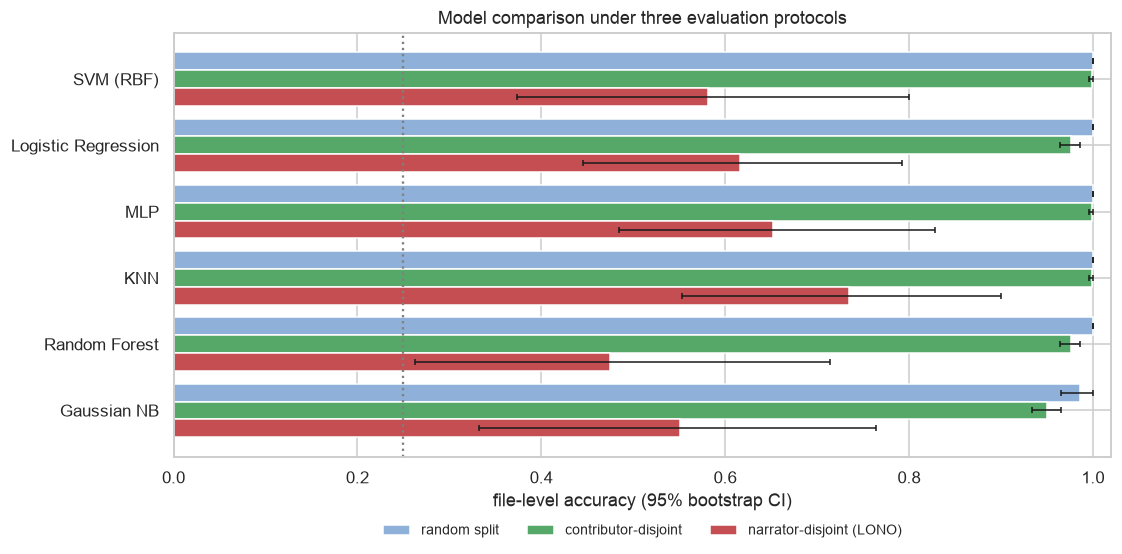

In [5]:
def bootstrap_ci(d, by=None, n=2000, seed=RS):
    rng = np.random.default_rng(seed)
    ok = (d.y_true == d.y_pred).to_numpy()
    if by is None:
        s = rng.choice(ok, size=(n, len(ok))).mean(1)
    else:
        g = d[by].to_numpy(); u = np.unique(g)
        hits = np.array([ok[g == x].sum() for x in u]); cnt = np.array([(g == x).sum() for x in u])
        idx = rng.integers(0, len(u), size=(n, len(u)))
        s = hits[idx].sum(1) / cnt[idx].sum(1)
    return pd.Series({"accuracy": ok.mean(), "ci_low": np.percentile(s, 2.5), "ci_high": np.percentile(s, 97.5)})

rows = []
for proto, f in file_pred.items():
    f = f.join(meta[["narrator"]], on="file_id")
    for m, d in f.groupby("model"):
        rows.append({"protocol": proto, "model": m, **bootstrap_ci(d, by="narrator" if "narrator" in proto else None)})
ci = pd.DataFrame(rows)
ci.to_csv(C.RESULTS_DIR / "accuracy_by_protocol.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#8fb0d9", "#55A868", "#C44E52"]
for i, proto in enumerate(PROTOCOLS):
    d = ci[ci.protocol == proto].set_index("model").reindex(ORDER)
    y = np.arange(len(d)) + (i - 1) * 0.27
    ax.barh(y, d.accuracy, height=0.27, label=proto, color=colors[i])
    ax.errorbar(d.accuracy, y, xerr=[d.accuracy - d.ci_low, d.ci_high - d.accuracy], fmt="none", c="k", capsize=2, lw=1)
ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(ORDER); ax.invert_yaxis()
ax.axvline(0.25, ls=":", c="gray"); ax.set_xlim(0, 1.02); ax.set_xlabel("file-level accuracy (95% bootstrap CI)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9, frameon=False); ax.set_title("Model comparison under three evaluation protocols")
plotting.save(fig, "04_model_comparison")
ci.pivot(index="model", columns="protocol", values="accuracy").reindex(ORDER)[list(PROTOCOLS)].round(3)

In [6]:
metrics_lono = pd.concat({"segment (10 s)": table(seg_pred["narrator-disjoint (LONO)"]),
                          "file (~1 min)": table(file_pred["narrator-disjoint (LONO)"])}, axis=1)
metrics_lono.to_csv(C.RESULTS_DIR / "metrics_narrator_lono.csv")
table(file_pred["contributor-disjoint"]).to_csv(C.RESULTS_DIR / "metrics_contributor_cv.csv")
metrics_lono.style.format("{:.3f}").background_gradient(cmap="Reds", axis=0)

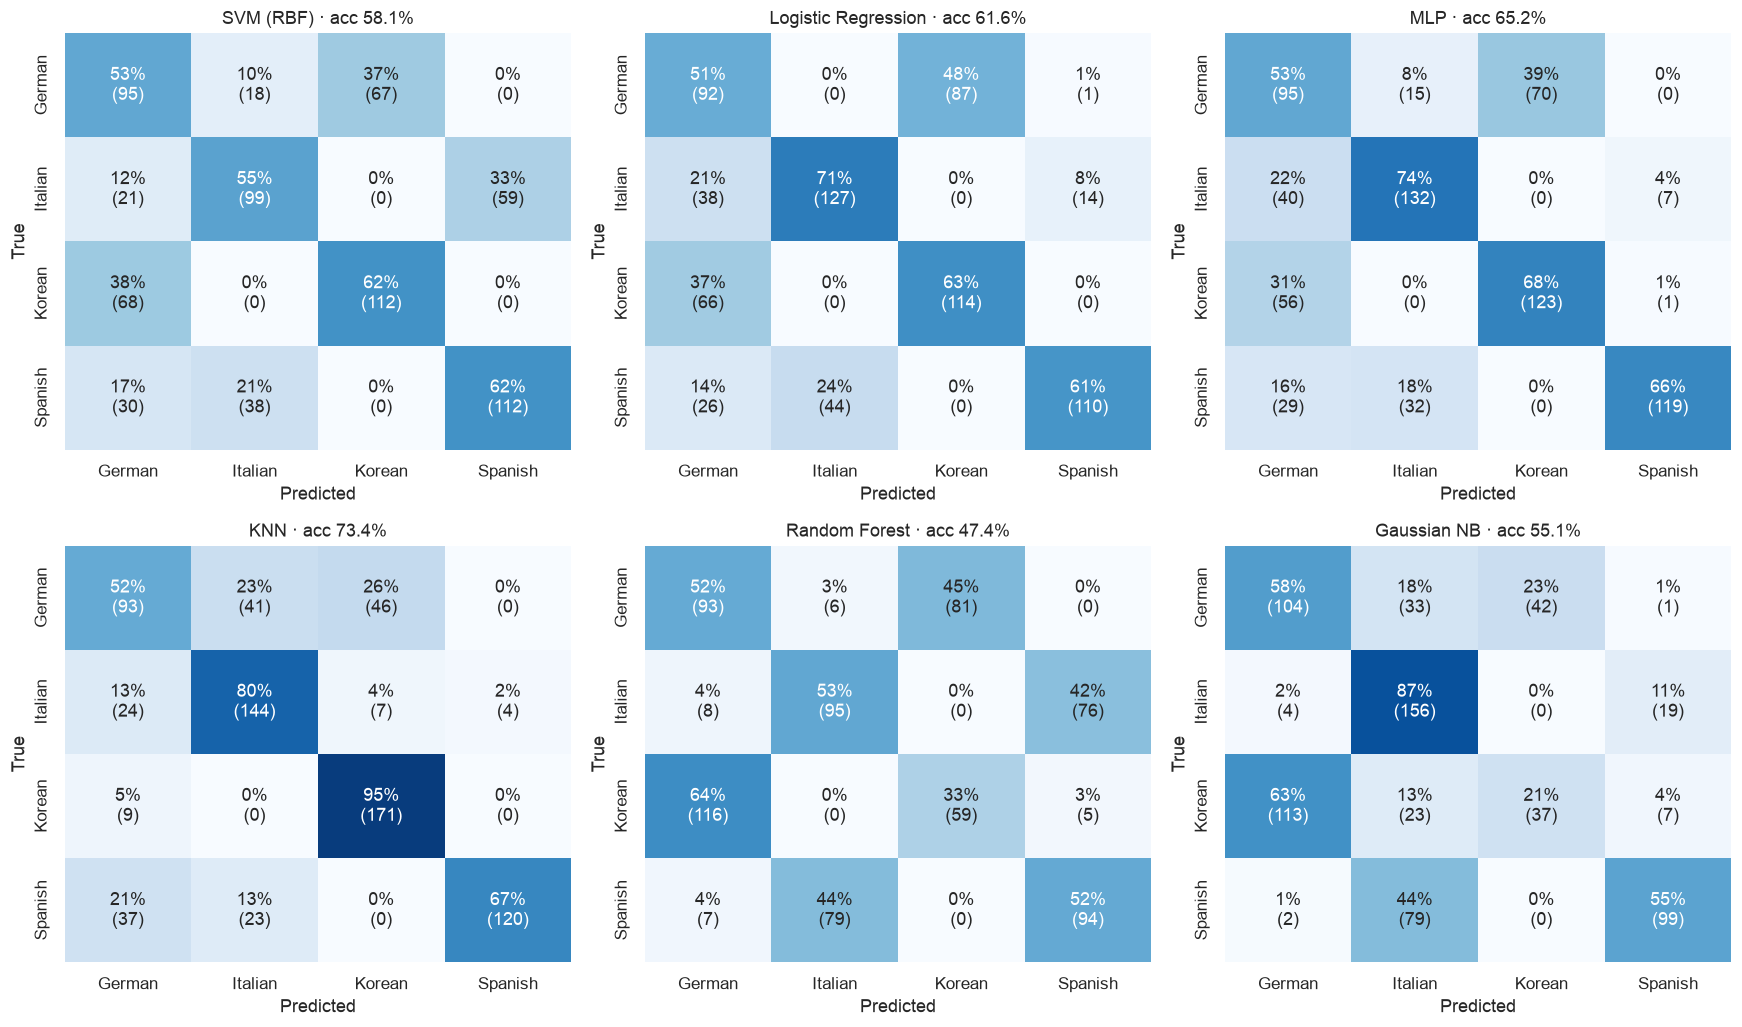

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
fl = file_pred["narrator-disjoint (LONO)"]
for ax, m in zip(axes.flat, ORDER):
    d = fl[fl.model == m]
    plotting.confusion(ax, d.y_true, d.y_pred, f"{m} · acc {np.mean(d.y_true == d.y_pred):.1%}")
plt.tight_layout(); plotting.save(fig, "04_confusion_narrator_lono")

Best narrator-disjoint model: KNN

              precision    recall  f1-score   support

      German      0.571     0.517     0.542       180
     Italian      0.692     0.804     0.744       179
      Korean      0.763     0.950     0.847       180
     Spanish      0.968     0.667     0.789       180

    accuracy                          0.734       719
   macro avg      0.748     0.734     0.731       719
weighted avg      0.749     0.734     0.731       719



,language,gender,narrator,accuracy,files,most predicted
0,German,female,N01,1.000000,47,German
1,German,female,N02,1.000000,40,German
2,German,female,N03,0.000000,3,Italian
3,German,male,N04,0.000000,44,Korean
4,German,male,N05,0.130435,46,Italian
5,Italian,female,N06,0.562500,80,Italian
6,Italian,female,N07,1.000000,10,Italian
7,Italian,male,N08,1.000000,14,Italian
8,Italian,male,N09,1.000000,14,Italian
9,Italian,male,N10,1.000000,12,Italian


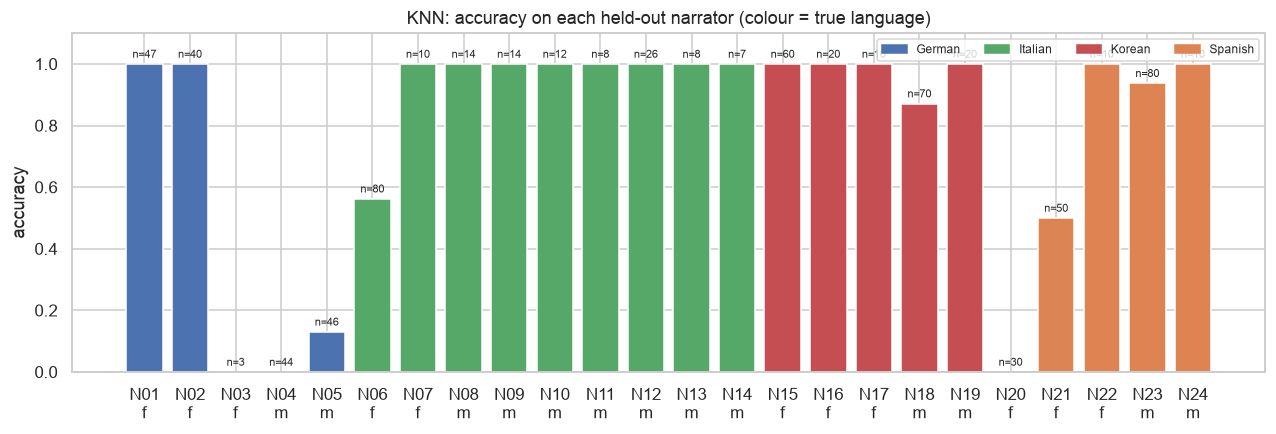

In [8]:
best_lono = table(fl).f1_macro.idxmax()
d = fl[fl.model == best_lono].join(meta[["narrator", "gender", "language"]], on="file_id")
print(f"Best narrator-disjoint model: {best_lono}\n")
print(classification_report(d.y_true, d.y_pred, target_names=C.LANGUAGES, digits=3))

per = d.groupby(["language", "gender", "narrator"]).apply(
    lambda g: pd.Series({"accuracy": (g.y_true == g.y_pred).mean(), "files": len(g),
                         "most predicted": C.LANGUAGES[g.y_pred.mode()[0]]})).reset_index()
fig, ax = plt.subplots(figsize=(14, 4))
per = per.sort_values(["language", "gender", "narrator"])
bars = ax.bar(per.narrator + "\n" + per.gender.str[0], per.accuracy, color=per.language.map(plotting.LANG_COLORS))
for b, f in zip(bars, per.files): ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"n={f}", ha="center", fontsize=7)
ax.set_ylim(0, 1.1); ax.set_ylabel("accuracy"); ax.set_title(f"{best_lono}: accuracy on each held-out narrator (colour = true language)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in plotting.LANG_COLORS.values()]
ax.legend(handles, C.LANGUAGES, ncol=4, loc="upper right", fontsize=8)
plotting.save(fig, "04_per_narrator")
per

**Unseen narrators.**

* The confidence intervals are wide (resampling narrators): with only 24 voices, a single narrator moves accuracy by
  several points. The ranking KNN > MLP > LR > SVM > NB > RF is consistent with notebook 2.
* By language (best model, KNN): **Korean** is recognised best (recall 0.95), **Spanish** is rarely predicted wrongly (precision 0.97) but
  often missed (recall 0.67), and **German** is hardest (F1 0.54).
* Two confusion patterns appear for all models:
  **Spanish ↔ Italian**, which is linguistically plausible, and **German ↔ Korean**, which is not and shows that the models
  partly match voices rather than languages.
* Errors are concentrated in a few narrators. Most held-out narrators are classified 100 % correctly, but both
  **German-male** narrators fail (N04 → Korean, N05 13 %), as does one Spanish-female narrator (N20 → German).
  German male has only **two** narrators: when one is held out, the model has seen a single German male voice and cannot
  tell which properties belong to *German* and which to *that narrator*.
* **More speech does not help unseen narrators.** On the random split accuracy saturates after 10–30 s. In LONO it is
  flat (KNN 72 % with 10 s, 73 % with 60 s): the errors are systematic per voice, not random noise that averaging could
  remove. More *narrators* would help; more audio per narrator does not.

## 4.3 How much speech is needed?

Short segments are one of the main LID challenges. The file-level decision is recomputed from only the first *n* segments
(n × 10 s of speech), for the random split and the narrator-disjoint protocol.

seconds                                          10     20     30     40  \
protocol                 model                                             
narrator-disjoint (LONO) Gaussian NB          0.523  0.541  0.549  0.554   
                         KNN                  0.718  0.709  0.733  0.729   
                         Logistic Regression  0.605  0.609  0.622  0.622   
                         MLP                  0.652  0.650  0.643  0.648   
                         Random Forest        0.480  0.470  0.465  0.469   
                         SVM (RBF)            0.609  0.590  0.579  0.576   
random split             Gaussian NB          0.965  0.972  0.986  0.986   
                         KNN                  1.000  0.993  1.000  1.000   
                         Logistic Regression  0.993  1.000  1.000  1.000   
                         MLP                  1.000  1.000  1.000  1.000   
                         Random Forest        1.000  1.000  1.000  1.000   
                         SVM (RBF)            1.000  1.000  1.000  1.000   

seconds                                          50     60  
protocol                 model                              
narrator-disjoint (LONO) Gaussian NB          0.554  0.549  
                         KNN                  0.732  0.733  
                         Logistic Regression  0.618  0.618  
                         MLP                  0.647  0.652  
                         Random Forest        0.474  0.474  
                         SVM (RBF)            0.580  0.580  
random split             Gaussian NB          0.986  0.986  
                         KNN                  1.000  1.000  
                         Logistic Regression  1.000  1.000  
                         MLP                  1.000  1.000  
                         Random Forest        1.000  1.000  
                         SVM (RBF)            1.000  1.000

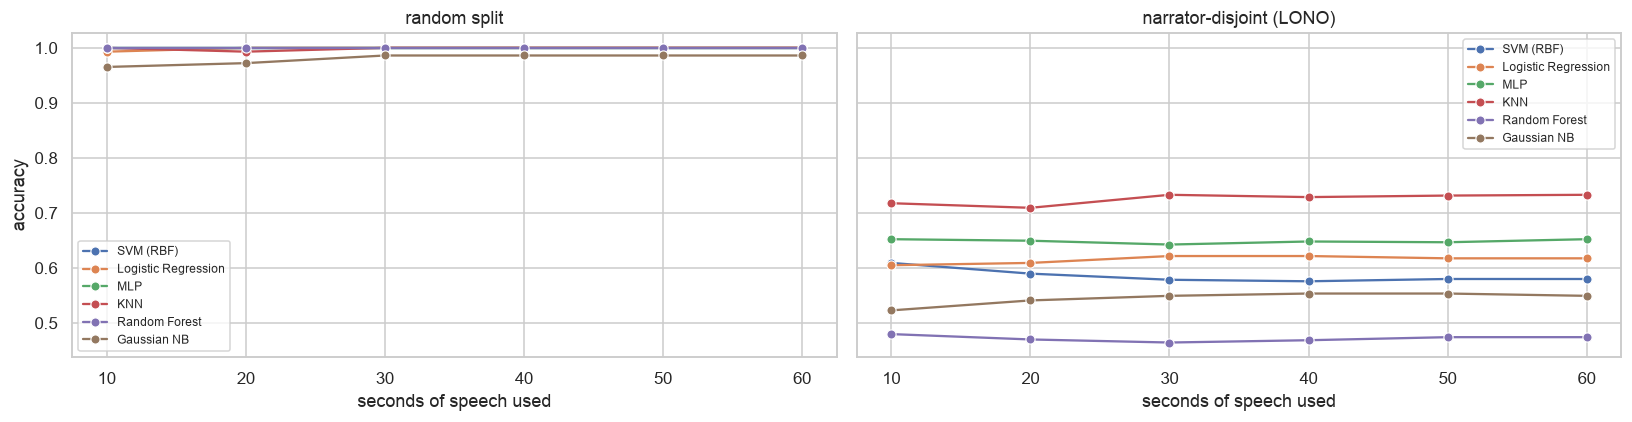

In [9]:
rows = []
for proto in ["random split", "narrator-disjoint (LONO)"]:
    sp = seg_pred[proto]
    for n in range(1, 7):
        agg = models.file_level(sp[sp.segment < n], PROBA)
        for m, dd in agg.groupby("model"):
            rows.append({"protocol": proto, "model": m, "seconds": 10 * n, "accuracy": (dd.y_true == dd.y_pred).mean()})
dur = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, proto in zip(axes, ["random split", "narrator-disjoint (LONO)"]):
    sns.lineplot(data=dur[dur.protocol == proto], x="seconds", y="accuracy", hue="model", hue_order=ORDER, marker="o", ax=ax)
    ax.set_title(proto); ax.set_xlabel("seconds of speech used"); ax.legend(fontsize=8)
plt.tight_layout(); plotting.save(fig, "04_accuracy_vs_duration")
dur.pivot_table(index=["protocol", "model"], columns="seconds", values="accuracy").round(3)

## 4.4 Ablations (narrator-disjoint)

Logistic Regression (fast, and competitive in every protocol) is retrained with leave-one-narrator-out CV to answer:

* Does **augmentation** help on unseen narrators?
* Which **feature groups** generalise? Each group alone, all features minus one group, and a
  **channel-robust set** (only dynamic or speaker-normalised features: MFCC Δ/ΔΔ, SDC on mean-normalised cepstra,
  F0 in semitones, rhythm), which by construction ignores the static spectral colour of a voice or microphone.

In [10]:
seg = pd.read_parquet(C.PROCESSED_DIR / "segment_features.parquet").merge(meta[["label", "narrator"]], left_on="file_id", right_index=True)
FEATS = features.feature_columns(seg.columns)
NARR = sorted(seg.narrator.unique())
base = joblib.load(C.MODELS_DIR / "logistic_regression.joblib")
ROBUST = [c for c in FEATS if c.startswith(("mfcc_d1", "mfcc_d2", "sdc_", "f0_", "rhythm_"))]

def lono(cols, use_aug=True):
    preds = []
    for g in NARR:
        tr = seg[(seg.narrator != g) & (use_aug | (seg.aug == "none"))]
        te = seg[(seg.narrator == g) & (seg.aug == "none")]
        m = clone(base).fit(tr[cols].to_numpy(), tr.label.to_numpy())
        p = te[["file_id", "segment"]].assign(y_true=te.label.to_numpy(), model="lr")
        p[PROBA] = m.predict_proba(te[cols].to_numpy()); preds.append(p)
    p = pd.concat(preds); f = models.file_level(p, PROBA)
    return {"n_features": len(cols), "segment_acc": (p[PROBA].to_numpy().argmax(1) == p.y_true).mean(),
            "file_acc": (f.y_true == f.y_pred).mean(), "file_f1_macro": models.metrics(f.y_true, f.y_pred)["f1_macro"]}

jobs = {("augmentation", "with augmentation"): (FEATS, True),
        ("augmentation", "without augmentation"): (FEATS, False),
        ("feature set", "all features"): (FEATS, True),
        ("feature set", "channel-robust set"): (ROBUST, True)}
for g in features.FEATURE_GROUPS:
    jobs[("only this group", g)] = (features.feature_columns(FEATS, [g]), True)
    jobs[("all except this group", g)] = ([c for c in FEATS if c.split("_")[0] != g], True)
out = Parallel(n_jobs=-1)(delayed(lono)(cols, aug) for cols, aug in jobs.values())
abl = pd.DataFrame(out, index=pd.MultiIndex.from_tuples(jobs.keys(), names=["experiment", "setting"]))
abl.to_csv(C.RESULTS_DIR / "ablations_narrator_lono.csv")
abl.loc[["augmentation", "feature set"]].round(3)

n_features  segment_acc  file_acc  \
experiment   setting                                                   
augmentation with augmentation            381        0.600     0.616   
             without augmentation         381        0.499     0.470   
feature set  all features                 381        0.600     0.616   
             channel-robust set           199        0.532     0.579   

                                   file_f1_macro  
experiment   setting                              
augmentation with augmentation             0.626  
             without augmentation          0.485  
feature set  all features                  0.626  
             channel-robust set            0.589

,dims,only this group,all minus group (Δ)
setting,,,
mel,80,0.618,0.001
mfcc,120,0.495,0.011
contrast,14,0.458,-0.006
sdc,98,0.426,0.008
spec,8,0.330,0.008
rhythm,14,0.327,0.010
f0,7,0.309,0.031
zcr,2,0.275,-0.008
chroma,24,0.255,0.000


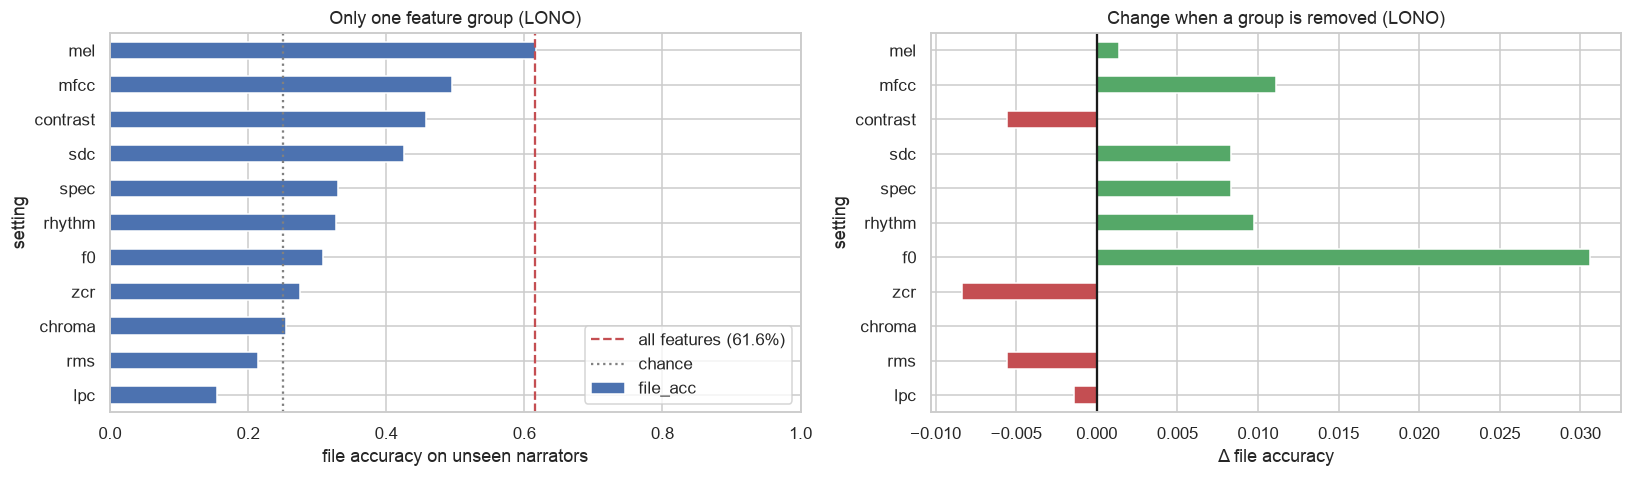

In [11]:
full = abl.loc[("feature set", "all features"), "file_acc"]
only = abl.loc["only this group"].file_acc.sort_values()
drop = (abl.loc["all except this group"].file_acc - full).reindex(only.index)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
only.plot.barh(ax=axes[0], color="#4C72B0"); axes[0].axvline(full, ls="--", c="C3", label=f"all features ({full:.1%})")
axes[0].axvline(0.25, ls=":", c="gray", label="chance"); axes[0].legend(loc="lower right"); axes[0].set_xlim(0, 1)
axes[0].set_title("Only one feature group (LONO)"); axes[0].set_xlabel("file accuracy on unseen narrators")
drop.plot.barh(ax=axes[1], color=np.where(drop < 0, "#C44E52", "#55A868"))
axes[1].axvline(0, c="k"); axes[1].set_title("Change when a group is removed (LONO)"); axes[1].set_xlabel("Δ file accuracy")
plt.tight_layout(); plotting.save(fig, "04_feature_ablation")
pd.DataFrame({"dims": abl.loc["only this group"].n_features, "only this group": only,
              "all minus group (Δ)": drop}).sort_values("only this group", ascending=False).round(3)

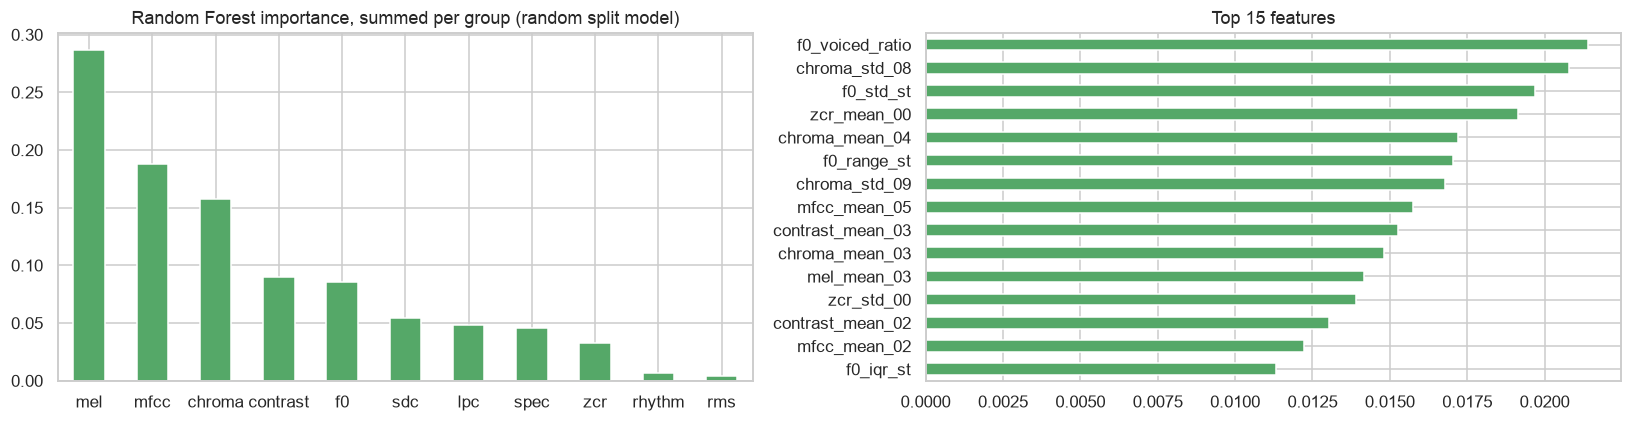

In [12]:
rf = joblib.load(C.MODELS_DIR / "random_forest.joblib")
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=FEATS)
by_group = imp.groupby(lambda c: c.split("_")[0]).sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
by_group.plot.bar(ax=axes[0], color="#55A868", rot=0); axes[0].set_title("Random Forest importance, summed per group (random split model)")
imp.nlargest(15).sort_values().plot.barh(ax=axes[1], color="#55A868"); axes[1].set_title("Top 15 features")
plt.tight_layout(); plotting.save(fig, "04_rf_importance")

**Ablations (Logistic Regression, leave-one-narrator-out).**

* **Augmentation is the single biggest improvement: 47.0 % → 61.6 % file accuracy (+14.6 points).** Speed perturbation and
  pitch shifting create "new" voices, which is exactly what is missing. On the random split it makes no difference,
  because that protocol is already saturated.
* **Feature groups alone:** log-mel (62 %) is as good as all features together (62 %), followed by MFCC (50 %),
  spectral contrast (46 %) and SDC (43 %). Spectral shape, rhythm and F0 alone reach 31–33 %, just above chance.
  Chroma is at chance (25.5 %), and LPC alone is *below* chance (15 %): its vocal-tract description matches voices
  across languages, so it is systematically misleading for new narrators.
* **Redundancy:** removing any single group changes accuracy by at most 3 points. Removing **F0** *improves* accuracy by
  3 points – absolute pitch (`f0_median_hz`) and voicing are narrator cues.
* The **channel-robust set** (dynamic and speaker-normalised features only) reaches 58 %, slightly below all features:
  static spectra also carry real language information (phoneme inventory), not only channel and voice.
* **Random Forest importances** (fitted on the random split) rank mel, MFCC and **chroma** highest, and the single most
  important feature is `f0_voiced_ratio`. These are exactly the narrator-specific cues that do not transfer, which is
  why the forest is the weakest model on unseen narrators.

## 4.5 Clustering metrics

,n_clusters,silhouette,purity_language,ARI_language,NMI_language,purity_gender,ARI_gender,purity_narrator,NMI_narrator
K-Means (k=4),4.000,0.206,0.581,0.279,0.384,0.823,0.279,0.389,0.618
K-Means (k=15),15.000,0.305,0.994,0.430,0.692,1.000,0.169,0.841,0.932
Agglomerative (k=4),4.000,0.201,0.581,0.282,0.389,0.805,0.250,0.389,0.632
Agglomerative (k=16),16.000,0.306,0.999,0.420,0.690,1.000,0.163,0.851,0.940
GMM (k=4),4.000,0.138,0.597,0.279,0.426,0.834,0.244,0.401,0.579
"GMM (k=10, BIC)",10.000,0.245,0.880,0.391,0.636,0.897,0.142,0.730,0.848
DBSCAN,14.000,0.293,0.889,0.380,0.630,0.950,0.181,0.782,0.916


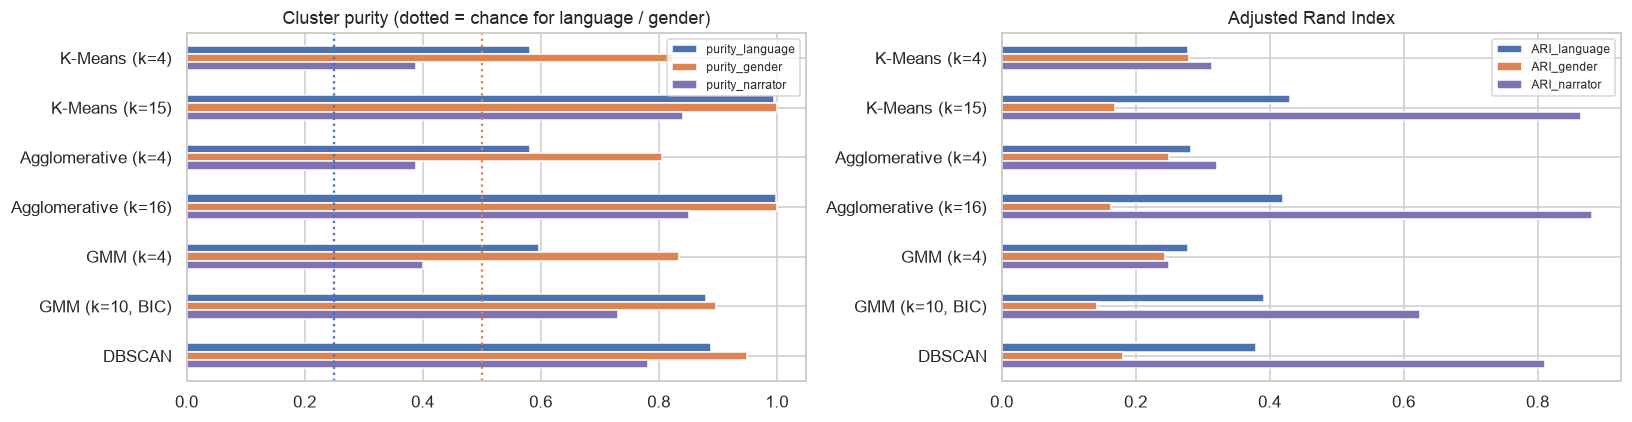

In [13]:
cl = pd.read_csv(C.RESULTS_DIR / "clustering_metrics.csv", index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
cl[["purity_language", "purity_gender", "purity_narrator"]].plot.barh(ax=axes[0], color=["#4C72B0", "#DD8452", "#8172B3"])
axes[0].axvline(0.25, ls=":", c="#4C72B0"); axes[0].axvline(0.5, ls=":", c="#DD8452"); axes[0].set_title("Cluster purity (dotted = chance for language / gender)")
cl[["ARI_language", "ARI_gender", "ARI_narrator"]].plot.barh(ax=axes[1], color=["#4C72B0", "#DD8452", "#8172B3"]); axes[1].set_title("Adjusted Rand Index")
for ax in axes: ax.invert_yaxis(); ax.legend(fontsize=8)
plt.tight_layout(); plotting.save(fig, "04_clustering_metrics")
cl[["n_clusters", "silhouette", "purity_language", "ARI_language", "NMI_language", "purity_gender", "ARI_gender", "purity_narrator", "NMI_narrator"]].style.format("{:.3f}")

**Clustering.** At k = 4 the clusters agree with language only weakly (purity ≈ 0.6, ARI ≈ 0.28) and more with gender
(purity ≈ 0.82). At the silhouette-optimal k = 15–16 they are language-pure, but only because each cluster is one narrator
(narrator NMI ≈ 0.94).

## Conclusions

1. On the standard random 80/20 split, **every model except Naïve Bayes reaches 100 % file-level accuracy** (≥ 99.6 % on
   10 s segments). The task looks solved.
2. The dataset contains only **~24 distinct narrators** for 719 clips. Accuracy on **narrators never seen in training is
   47–73 %**, so the near-perfect score mostly reflects recognising voices and recordings.
3. **LDA + KNN generalises best** (73 %); flexible models (Random Forest, RBF-SVM) overfit narrator-specific cues.
   **Augmentation** (+15 points) is the most effective remedy among those tested.
4. Clustering leads to the same conclusion: the feature space is organised by narrator first, gender second, and language
   third.

**Limitations and next steps**

* Narrator groups are estimated from audio; knowing which audiobook each contributor used would give the exact grouping.
* The most effective improvement would be **more narrators per language and gender** (currently often only 2).
* Speaker-invariant representations would likely help: x-vectors / ECAPA trained for language ID, self-supervised
  speech embeddings (wav2vec 2.0, XLS-R), or narrator-adversarial training that removes speaker information.
* Phonotactic approaches (phone recognisers + n-gram language models) rely on phone sequences rather than timbre and
  are a classic way to make LID less sensitive to the speaker.